## Atelier pratique : K-Nearest Neighbors (KNN)

### 1. Présentation de l'algorithme

Dans cet atelier, nous allons découvrir un algorithme du machine learning appelé KNN, qui signifie K-Nearest Neighbors, c’est-à-dire en français « les K plus proches voisins ». Le principe est très simple et vous l’utilisez déjà dans la vie de tous les jours : quand vous arrivez dans un endroit que vous ne connaissez pas, vous regardez ce que font les personnes les plus proches de vous pour décider quoi faire. Le KNN fonctionne de la même manière : pour deviner la réponse sur une nouvelle donnée, il regarde les K données les plus proches parmi celles qu’il connaît déjà, et choisit la réponse la plus fréquente parmi elles.

KNN est un algorithme simple et intuitif, utilisé principalement pour les problèmes de classification et de régression.

**Le KNN repose sur une idée intuitive : « Dis-moi qui sont tes voisins, je te dirai qui tu es »**

### 2. Objectifs de l'atelier
L'objectif de cet atelier est de comprendre le fonctionnement de l'algorithme KNN, de l'implémenter en Python et de l'appliquer à un problème concret de Machine Learning supervisé. Nous étudierons également l'influence du choix de \(K\), l'importance de la normalisation des données et les méthodes permettant d'évaluer et d'améliorer les performances du modèle.

### 3. Compétences à acquérir

À la fin de cet atelier, vous serez capables de :

- Comprendre le fonctionnement du KNN et le rôle du paramètre K.
- Calculer les distances entre les observations et comprendre leur importance.
- Préparer et normaliser les données.
- Implémenter un modèle KNN avec Scikit-learn.
- Évaluer les performances du modèle avec les métriques de classification.
- Optimiser le choix de K et comprendre les limites de l'algorithme.

### 4.Principe de fonctionnement du KNN
KNN (K-Nearest Neighbors) est un algorithme de Machine Learning supervisé qui repose sur une idée simple : des observations similaires ont tendance à avoir des résultats similaires.

Contrairement à certains algorithmes, KNN ne construit pas un modèle complexe pendant l'entraînement. Il conserve les données d'entraînement et recherche les voisins les plus proches lorsqu'une nouvelle observation doit être prédite.

**Que signifie K dans KNN ?**
Le paramètre K représente le nombre de voisins les plus proches à considérer pour effectuer une prédiction.

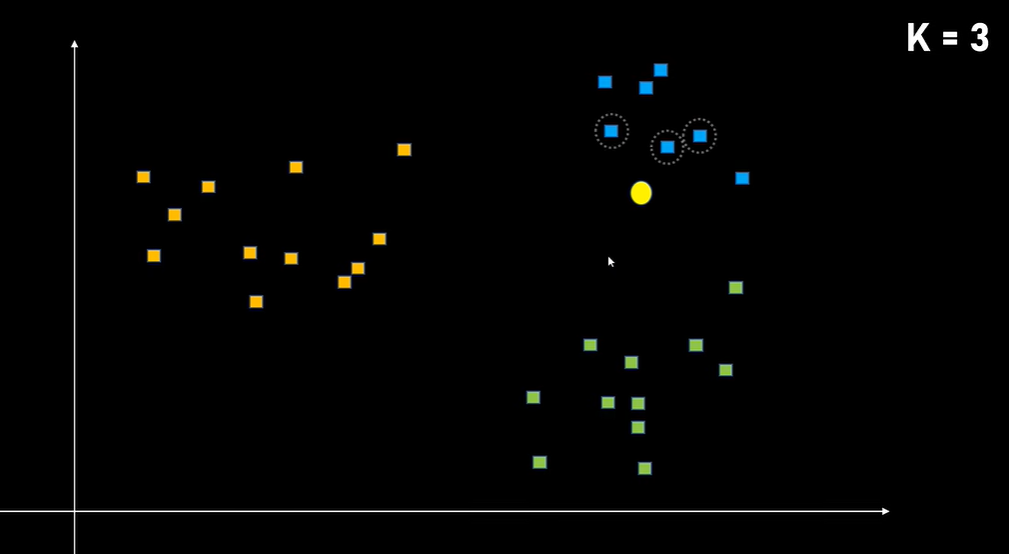

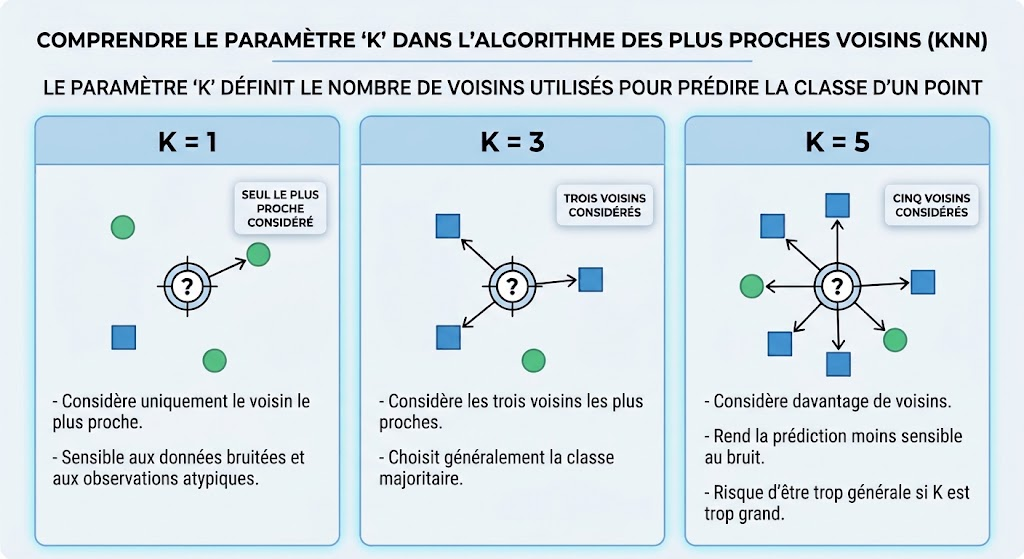

Influence du paramètre K sur la prédiction
Le paramètre K détermine le nombre de voisins les plus proches que l'algorithme KNN prend en compte pour prédire la classe d'une nouvelle observation.

Observons les trois situations illustrées ci-dessus :

Cas 1 : K = 1
L'algorithme considère uniquement le voisin le plus proche du point à prédire. La classe de ce voisin détermine la prédiction.

- Avantage : le modèle prend en compte les observations les plus proches.

- Inconvénient : il est très sensible au bruit et aux valeurs aberrantes.

Cas 2 : K = 3

L'algorithme considère les trois voisins les plus proches et attribue généralement au point la classe majoritaire parmi ces voisins.

Par exemple, si deux voisins appartiennent à la classe A et un à la classe B, le point sera classé dans la classe A.

Cette approche réduit la dépendance à un seul voisin.

Cas 3 : K = 5

L'algorithme considère les cinq voisins les plus proches. La prédiction repose sur un ensemble plus large d'observations.

- Avantage : la prédiction peut être moins sensible au bruit.

- Inconvénient : si K est trop grand, des voisins éloignés ou appartenant à d'autres groupes peuvent influencer la prédiction.

À retenir : un K trop élevé peut entraîner du sous-apprentissage en rendant le modèle moins sensible aux particularités locales. Toutefois, cet exemple illustre surtout le mécanisme du vote majoritaire : pour confirmer un véritable sous-apprentissage, il faudrait comparer les performances obtenues avec différentes valeurs de K.

**Exemple de sous-apprentissage (Underfitting) avec KNN**

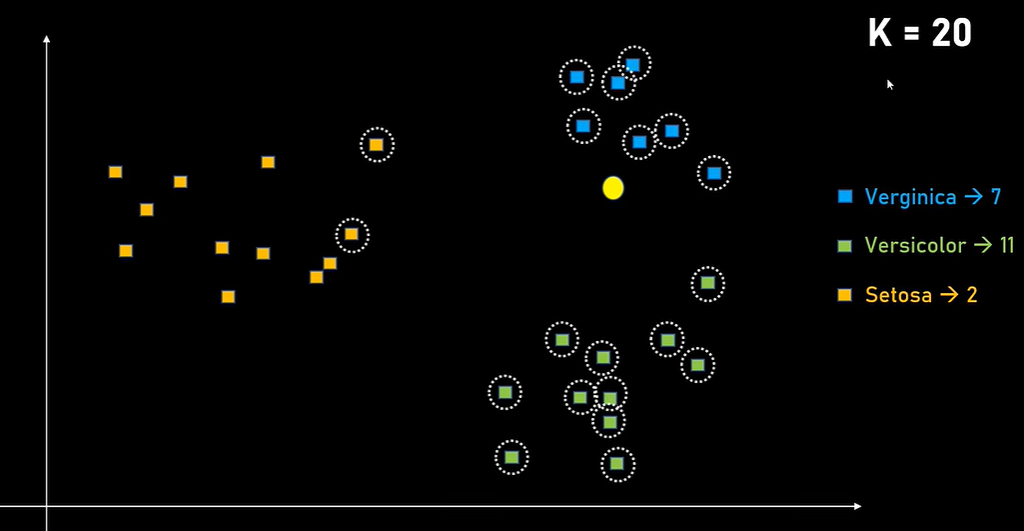

Dans cet exemple, nous voulons déterminer la classe à laquelle appartient le point jaune. Visuellement, il semble appartenir au groupe bleu (Virginica).

Cependant, nous avons choisi une valeur de K = 20. L'algorithme prend donc en compte les 20 voisins les plus proches du point jaune : 7 appartiennent à la classe Virginica (bleu), 11 à la classe Versicolor (vert) et 2 à la classe Setosa (orange).

Or, la règle du KNN consiste à attribuer au point la classe majoritaire parmi ses K voisins. Comme la classe verte compte le plus grand nombre de voisins, l'algorithme classe incorrectement le point jaune dans la catégorie Versicolor, alors qu'il semble appartenir au groupe bleu.

Cela illustre le risque d'un K trop grand : en considérant trop de voisins, l'algorithme peut inclure des observations appartenant à d'autres groupes et perdre en précision locale.

Conclusion : un K trop grand peut rendre les prédictions trop générales et favoriser le sous-apprentissage (underfitting). Toutefois, une seule erreur de classification ne suffit pas à prouver un sous-apprentissage ; il faut également évaluer les performances du modèle sur plusieurs observations.

**Exemple de surapprentissage (Overfitting)**

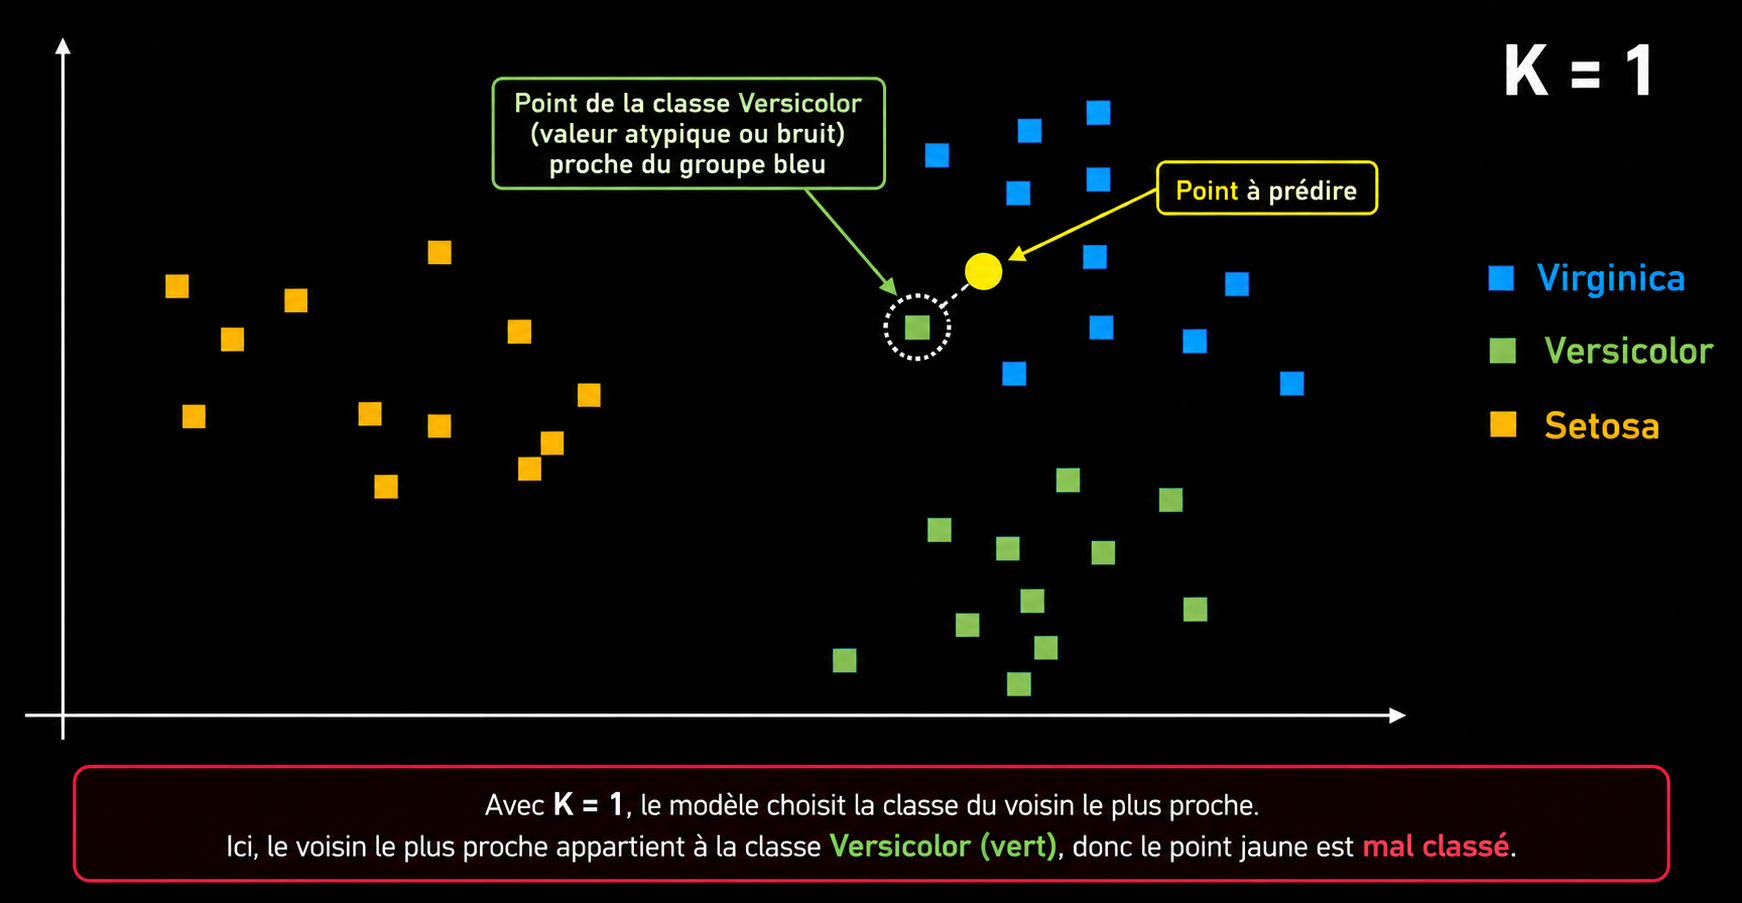

Exemple de surapprentissage (Overfitting) : Avec K = 1, l'algorithme se base uniquement sur le voisin le plus proche. Ici, un outlier (valeur aberrante) de la classe Versicolor, situé près du groupe Virginica, entraîne une mauvaise classification du point jaune. Cela illustre la sensibilité du KNN aux observations atypiques lorsque K est trop petit.

**Distance euclidienne:**

C'est la mesure de distance la plus classique pour comprendre KNN.

Pour deux points \(A\) et \(B\) possédant \(n\) caractéristiques :

$$
d(A,B) = \sqrt{\sum_{i=1}^{n}(A_i - B_i)^2}
$$

**Distance de Manhattan:**

Elle correspond à la somme des différences absolues entre les coordonnées :
$$
d(A,B) = \sum_{i=1}^{n} |A_i - B_i|
$$

### 5. Utilisation du KNN

Le KNN peut être utilisé pour résoudre deux types de problèmes en apprentissage supervisé :

**5.1. KNN pour la classification :**

Le KNN peut être utilisé pour résoudre deux types de problèmes en apprentissage supervisé :
L'objectif est de prédire une catégorie à partir des classes des K voisins les plus proches. L'algorithme utilise généralement le vote majoritaire pour déterminer la classe prédite.

Exemple : prédire si un fruit est une pomme ou une orange à partir de ses caractéristiques.

**5.2. KNN pour la régression :**

L'objectif est de prédire une valeur numérique à partir des valeurs cibles des K voisins les plus proches. La prédiction correspond généralement à la moyenne des valeurs de ces voisins.


KNN prédit une valeur numérique en calculant généralement **la moyenne des valeurs** cibles des K voisins les plus proches. 


#### Exemple : KNN pour la régression

Contrairement à la classification, qui prédit une catégorie, la régression KNN prédit une valeur numérique à partir des valeurs des K voisins les plus proches.

**Situation :** Nous souhaitons estimer le prix d'une maison de 100 m². Pour cela, KNN identifie les 3 maisons les plus proches (K = 3) selon leurs caractéristiques.

| Maison | Surface | Prix |
|---|---:|---:|
| Maison A | 95 m² | 900 000 DH |
| Maison B | 105 m² | 1 000 000 DH |
| Maison C | 110 m² | 950 000 DH |

**Calcul de la prédiction**

KNN utilise généralement la moyenne des prix des K voisins :

$$
\hat{y} = \frac{1}{K}\sum_{i=1}^{K}y_i
$$

Pour K = 3 :

$$
\hat{y} = \frac{900000 + 1000000 + 950000}{3}
$$

$$
\boxed{\hat{y} = 950\,000\ \text{DH}}
$$

Le prix estimé de la maison est donc de **950 000 DH**.

**À retenir :**
- Identifier les K voisins les plus proches.
- Récupérer leurs valeurs numériques connues.
- Calculer leur moyenne pour obtenir la prédiction.

*Remarque :* dans cet exemple, les trois voisins sont supposés déjà identifiés. En pratique, KNN calcule les distances à partir des caractéristiques des maisons. Une variante pondérée donne davantage d'importance aux voisins les plus proches.


**Importer Pandas pour manipuler les données sous forme de tableau**

In [1]:
import pandas as pd

# Importer la fonction permettant de charger le dataset Iris
from sklearn.datasets import load_iris

# Charger le dataset Iris
iris = load_iris()

# Créer un DataFrame à partir des caractéristiques des fleurs
# Chaque colonne représente une caractéristique :
# longueur/largeur du sépale et longueur/largeur du pétale
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Ajouter la variable cible contenant la classe de chaque fleur
# 0 : Setosa, 1 : Versicolor, 2 : Virginica
df["target"] = iris.target

# Afficher les cinq premières observations pour découvrir les données
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# Afficher les dimensions du dataset : nombre de lignes et de colonnes
print("Dimensions du dataset :", df.shape)

# Afficher les informations générales : types des variables et valeurs non nulles
print("\nInformations sur le dataset :")
df.info()

# Vérifier le nombre de valeurs manquantes dans chaque colonne
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

# Examiner la répartition des observations dans chaque classe
print("\nRépartition des classes :")
print(df["target"].value_counts().sort_index())


Dimensions du dataset : (150, 5)

Informations sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB

Valeurs manquantes par colonne :
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Répartition des classes :
target
0    50
1    50
2    50
Name: count, dtype: int64


**Observer comment les caractéristiques des fleurs varient selon leur espèce et vérifier si les trois classes peuvent être distinguées visuellement.**

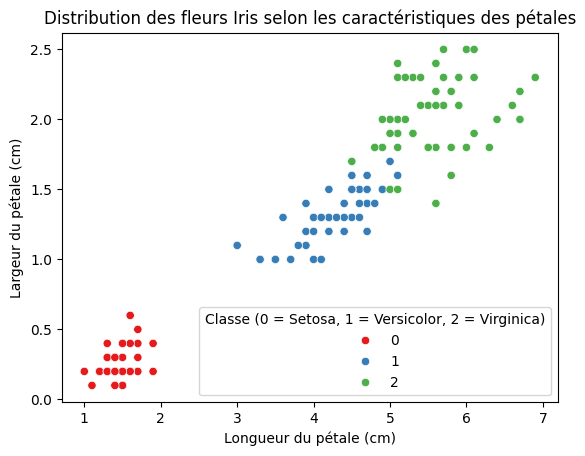

In [3]:

# Importer Seaborn pour créer des graphiques statistiques
import seaborn as sns

# Importer Matplotlib pour afficher le graphique
import matplotlib.pyplot as plt

# Visualiser la relation entre la longueur et la largeur des pétales
# Chaque point représente une fleur, colorée selon son espèce
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="target",
    palette="Set1"
)

# Ajouter un titre et des étiquettes aux axes
plt.title("Distribution des fleurs Iris selon les caractéristiques des pétales")
plt.xlabel("Longueur du pétale (cm)")
plt.ylabel("Largeur du pétale (cm)")

# Afficher la légende et le graphique
plt.legend(title="Classe (0 = Setosa, 1 = Versicolor, 2 = Virginica)")
plt.show()


**Séparation des variables X et y:**
séparer les caractéristiques utilisées pour effectuer les prédictions de la variable cible que le modèle KNN doit apprendre à prédire.

In [4]:

# X contient les caractéristiques utilisées par le modèle pour effectuer ses prédictions.
# On exclut la colonne "target", car elle représente la réponse que le modèle doit prédire.
X = df.drop(columns=["target"])

# y contient les classes réelles des fleurs que le modèle doit apprendre à prédire.
# 0 : Setosa, 1 : Versicolor, 2 : Virginica
y = df["target"]

# Vérifier les dimensions des deux ensembles.
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Afficher quelques exemples pour vérifier la séparation.
print("\nCaractéristiques (X) :")
display(X.head())

print("\nClasses à prédire (y) :")
display(y.head())


Dimensions de X : (150, 4)
Dimensions de y : (150,)

Caractéristiques (X) :


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Classes à prédire (y) :


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int32

In [5]:

# Importer la fonction permettant de diviser les données
from sklearn.model_selection import train_test_split

# Diviser les données :
# 80 % pour l'entraînement et 20 % pour le test
# random_state garantit la reproductibilité de la division
# stratify=y conserve approximativement la proportion de chaque classe
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Vérifier les dimensions des ensembles obtenus
print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)
print("Taille de y_train :", y_train.shape)
print("Taille de y_test  :", y_test.shape)


Taille de X_train : (120, 4)
Taille de X_test  : (30, 4)
Taille de y_train : (120,)
Taille de y_test  : (30,)


**Normalisation des données.**

Mettre les caractéristiques sur une échelle comparable, car KNN repose sur le calcul des distances. Une variable avec des valeurs beaucoup plus grandes pourrait influencer excessivement ces distances.

In [6]:

# Importer StandardScaler pour standardiser les caractéristiques
from sklearn.preprocessing import StandardScaler

# Créer le standardiseur
scaler = StandardScaler()

# Calculer les paramètres de standardisation uniquement sur les données d'entraînement
X_train_scaled = scaler.fit_transform(X_train)

# Appliquer les mêmes paramètres aux données de test
X_test_scaled = scaler.transform(X_test)

# Afficher les dimensions pour vérifier les résultats
print("Dimensions de X_train_scaled :", X_train_scaled.shape)
print("Dimensions de X_test_scaled  :", X_test_scaled.shape)


Dimensions de X_train_scaled : (120, 4)
Dimensions de X_test_scaled  : (30, 4)


**Entraînement du modèle KNN :**

créer et entraîner un premier modèle KNN avec \(K = 3\), en utilisant les données standardisées.

In [7]:
# Importer le classificateur KNN de Scikit-learn
from sklearn.neighbors import KNeighborsClassifier

# Créer le modèle en considérant les 3 voisins les plus proches
knn = KNeighborsClassifier(n_neighbors=3)

# Entraîner le modèle à partir des caractéristiques et des classes d'entraînement
knn.fit(X_train_scaled, y_train)

# Afficher une confirmation de l'entraînement
print("Le modèle KNN a été entraîné avec succès !")


Le modèle KNN a été entraîné avec succès !


**Prédiction sur les données de test**

utiliser le modèle KNN entraîné pour prédire l'espèce des fleurs présentes dans l'ensemble de test, puis comparer les prédictions aux classes réelles.

In [8]:

# Prédire les classes des fleurs à partir des caractéristiques de test standardisées
y_pred = knn.predict(X_test_scaled)

# Afficher les classes réelles et les classes prédites pour les 10 premières observations
resultats = pd.DataFrame({
    "Classe réelle": y_test.iloc[:10].values,
    "Classe prédite": y_pred[:10]
})

# Ajouter les noms des espèces pour faciliter l'interprétation
resultats["Espèce réelle"] = resultats["Classe réelle"].map(
    dict(enumerate(iris.target_names))
)
resultats["Espèce prédite"] = resultats["Classe prédite"].map(
    dict(enumerate(iris.target_names))
)

display(resultats)


,Classe réelle,Classe prédite,Espèce réelle,Espèce prédite
0,0,0,setosa,setosa
1,2,2,virginica,virginica
2,1,1,versicolor,versicolor
3,1,1,versicolor,versicolor
4,0,0,setosa,setosa
5,1,1,versicolor,versicolor
6,0,0,setosa,setosa
7,0,0,setosa,setosa
8,2,2,virginica,virginica
9,1,1,versicolor,versicolor


**Prédiction d'une nouvelle observation**

In [10]:

# Définir une nouvelle fleur avec les mêmes noms de caractéristiques que X
nouvelle_fleur = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Appliquer la standardisation avec le scaler déjà entraîné
nouvelle_fleur_scaled = scaler.transform(nouvelle_fleur)

# Prédire l'espèce de la nouvelle fleur
prediction = knn.predict(nouvelle_fleur_scaled)

# Convertir le numéro de classe en nom d'espèce
espece_predite = iris.target_names[prediction[0]]

print("Espèce prédite :", espece_predite)


Espèce prédite : setosa


**Évaluation du modèle KNN.**

Mesurer la qualité des prédictions en calculant l'accuracy et en examinant la matrice de confusion.

In [11]:

# Importer les métriques nécessaires à l'évaluation
from sklearn.metrics import accuracy_score, confusion_matrix

# Calculer l'accuracy : proportion de prédictions correctes
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy du modèle : {accuracy:.2%}")

# Construire la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Afficher la matrice sous forme de tableau
print("\nMatrice de confusion :")
print(cm)


Accuracy du modèle : 93.33%

Matrice de confusion :
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


**Optimisation du paramètre K**

tester différentes valeurs de K afin d'identifier celle qui offre les meilleures performances en validation croisée.

In [12]:

# Importer la fonction de validation croisée
from sklearn.model_selection import cross_val_score

# Définir les valeurs de K à tester
k_values = range(1, 21)

# Stocker le score moyen obtenu pour chaque valeur de K
scores = []

# Tester chaque valeur de K avec une validation croisée à 5 plis
for k in k_values:
    # Créer un modèle KNN avec la valeur de K courante
    model = KNeighborsClassifier(n_neighbors=k)

    # Évaluer le modèle sur les données d'entraînement uniquement
    cv_scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    # Enregistrer la moyenne des scores des 5 plis
    scores.append(cv_scores.mean())

# Identifier la valeur de K qui obtient le meilleur score moyen
best_k = list(k_values)[scores.index(max(scores))]
best_score = max(scores)

print("Meilleure valeur de K :", best_k)
print(f"Accuracy moyenne en validation croisée : {best_score:.2%}")


Meilleure valeur de K : 5
Accuracy moyenne en validation croisée : 96.67%


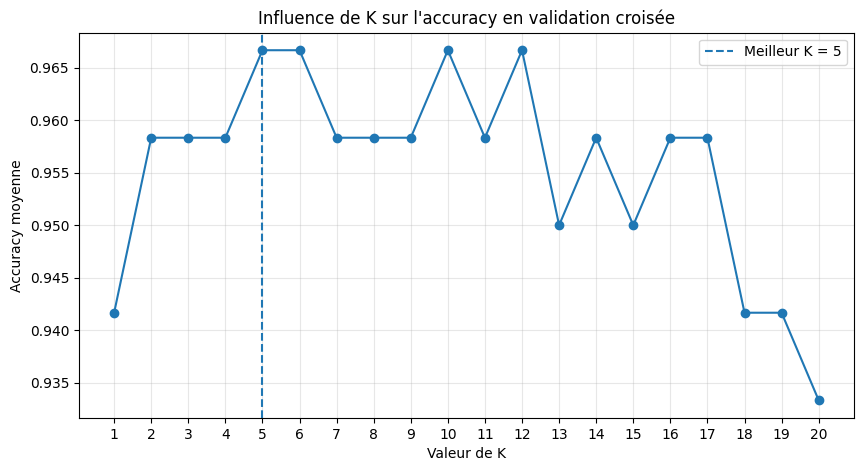

In [13]:
# Importer Matplotlib pour visualiser les résultats
import matplotlib.pyplot as plt

# Tracer l'accuracy moyenne obtenue pour chaque valeur de K
plt.figure(figsize=(10, 5))
plt.plot(list(k_values), scores, marker="o")

# Mettre en évidence la meilleure valeur de K
plt.axvline(best_k, linestyle="--", label=f"Meilleur K = {best_k}")

# Ajouter les titres et les étiquettes
plt.title("Influence de K sur l'accuracy en validation croisée")
plt.xlabel("Valeur de K")
plt.ylabel("Accuracy moyenne")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Ce graphique permettra d'identifier les valeurs de K qui donnent les meilleurs résultats, avant de réentraîner le modèle final avec K = 5 et de l'évaluer sur les données de test.

**Évaluation du modèle optimisé**

In [14]:

# Créer le modèle KNN avec la meilleure valeur de K trouvée
knn_final = KNeighborsClassifier(n_neighbors=best_k)

# Entraîner le modèle sur l'ensemble d'entraînement standardisé
knn_final.fit(X_train_scaled, y_train)

# Prédire les classes de l'ensemble de test
y_pred_final = knn_final.predict(X_test_scaled)

# Évaluer les prédictions sur les données jamais utilisées pour l'entraînement
accuracy_final = accuracy_score(y_test, y_pred_final)

print(f"Meilleure valeur de K : {best_k}")
print(f"Accuracy sur le jeu de test : {accuracy_final:.2%}")


Meilleure valeur de K : 5
Accuracy sur le jeu de test : 93.33%



### Conclusion

Dans cet atelier, nous avons étudié et implémenté l'algorithme **K-Nearest Neighbors (KNN)** pour résoudre un problème de classification à partir du dataset Iris.

Nous avons découvert le fonctionnement de KNN, les mesures de distance, l'importance de la normalisation des données et l'influence du paramètre K sur les prédictions. Nous avons ensuite entraîné et évalué un modèle avec Scikit-learn, puis utilisé la validation croisée pour rechercher une valeur de K adaptée.

Cet atelier nous a permis de comprendre les étapes essentielles de la construction d'un modèle de classification, de la préparation des données jusqu'à l'évaluation des performances.

**Points clés à retenir :**
- KNN repose sur la proximité entre les observations.
- La normalisation est importante lorsque les variables ont des échelles différentes.
- Le choix de K influence les performances du modèle.
- La validation croisée permet de comparer différentes configurations.
- L'évaluation sur un jeu de test permet d'estimer la capacité de généralisation du modèle.
